<a href="https://colab.research.google.com/github/uvindu827/J26-DS-350/blob/Indhi_Component2_CHL_Forecast/31_9P_16S_SHAP_Explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ======================================================================
# STEP 31.9P-16S-01
# SHAP ENVIRONMENT & FINAL MODEL VERIFICATION
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import xgboost as xgb

print("=" * 70)
print("STEP 31.9P-16S-01")
print("SHAP ENVIRONMENT & FINAL MODEL VERIFICATION")
print("=" * 70)

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

FINAL_TUNED_DIR = os.path.join(
    PROJECT,
    "06_models",
    "02_XGBoost",
    "hyperparameter_optimization",
    "final_tuned_candidate"
)

MODEL_PATH = os.path.join(
    FINAL_TUNED_DIR,
    "xgboost_final_tuned_candidate.json"
)

CONFIG_PATH = os.path.join(
    FINAL_TUNED_DIR,
    "xgboost_final_tuned_candidate_configuration.json"
)

FEATURE_PATH = os.path.join(
    PROJECT,
    "05_model_preprocessing",
    "final_model_feature_columns.csv"
)

TEST_DATA_PATH = os.path.join(
    PROJECT,
    "05_model_preprocessing",
    "final_model_ready_test.csv"
)

SHAP_DIR = os.path.join(
    FINAL_TUNED_DIR,
    "shap_explainability"
)

os.makedirs(SHAP_DIR, exist_ok=True)

print("\n" + "=" * 70)
print("PROJECT PATHS")
print("=" * 70)

print("Final tuned model:")
print(MODEL_PATH)

print("\nFinal configuration:")
print(CONFIG_PATH)

print("\nFeature list:")
print(FEATURE_PATH)

print("\nTest dataset:")
print(TEST_DATA_PATH)

print("\nSHAP output directory:")
print(SHAP_DIR)

# ----------------------------------------------------------------------
# FILE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "Final tuned XGBoost": MODEL_PATH,
    "Final tuned configuration": CONFIG_PATH,
    "Final feature list": FEATURE_PATH,
    "Final test dataset": TEST_DATA_PATH
}

for name, path in required_files.items():
    exists = os.path.exists(path)
    print(f"{name:35s}: {exists}")
    if not exists:
        raise FileNotFoundError(f"Required file not found: {path}")

print("\n✓ All required files found.")

# ----------------------------------------------------------------------
# SHAP CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP PACKAGE CHECK")
print("=" * 70)

try:
    import shap
    print("SHAP version:", shap.__version__)
except ImportError:
    raise ImportError(
        "SHAP is not installed. Run: !pip install -q shap"
    )

print("✓ SHAP package available.")

# ----------------------------------------------------------------------
# LOAD CONFIGURATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING LOCKED FINAL CONFIGURATION")
print("=" * 70)

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

for key in [
    "model",
    "objective",
    "n_estimators",
    "max_depth",
    "learning_rate",
    "subsample",
    "colsample_bytree",
    "min_child_weight",
    "reg_alpha",
    "reg_lambda",
    "random_state",
    "tree_method",
    "device",
    "early_stopping_rounds",
    "target",
    "original_target",
    "number_of_features",
    "best_iteration",
    "best_number_of_trees"
]:
    if key in config:
        print(f"{key:25s}: {config[key]}")

# ----------------------------------------------------------------------
# VERIFY EXPECTED FINAL CONFIGURATION
# ----------------------------------------------------------------------

expected = {
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 10,
    "reg_alpha": 0.0,
    "reg_lambda": 5.0,
    "random_state": 42,
    "n_estimators": 2000,
    "best_iteration": 70,
    "best_number_of_trees": 71
}

print("\n" + "=" * 70)
print("FINAL CONFIGURATION LOCK CHECK")
print("=" * 70)

configuration_ok = True

for key, expected_value in expected.items():

    actual_value = config.get(key)

    # Handle numeric values safely
    if isinstance(expected_value, float):
        match = np.isclose(
            float(actual_value),
            expected_value,
            rtol=0,
            atol=1e-12
        )
    else:
        match = actual_value == expected_value

    print(
        f"{key:25s}: "
        f"saved={actual_value} | "
        f"expected={expected_value}"
    )

    if not match:
        configuration_ok = False

if not configuration_ok:
    raise ValueError(
        "Final tuned XGBoost configuration does not match "
        "the locked configuration."
    )

print("\n✓ Final tuned configuration verified.")

# ----------------------------------------------------------------------
# LOAD FEATURE LIST
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING FINAL FEATURE LIST")
print("=" * 70)

feature_df = pd.read_csv(FEATURE_PATH)

features = feature_df["feature"].tolist()

print("Number of features:", len(features))

if len(features) != 69:
    raise ValueError(
        f"Expected exactly 69 features, found {len(features)}."
    )

print("✓ Exactly 69 final predictors confirmed.")

print("\nFirst 10 features:")
print(features[:10])

print("\nLast 10 features:")
print(features[-10:])

# ----------------------------------------------------------------------
# LOAD FINAL SAVED MODEL
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING FINAL SAVED TUNED XGBOOST")
print("=" * 70)

model = xgb.XGBRegressor()

model.load_model(MODEL_PATH)

print("✓ Final tuned XGBoost loaded.")

# ----------------------------------------------------------------------
# MODEL STRUCTURE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL STRUCTURE CHECK")
print("=" * 70)

booster = model.get_booster()

booster_features = booster.feature_names
booster_rounds = booster.num_boosted_rounds()

print("Stored model features :", len(booster_features))
print("Stored boosting rounds:", booster_rounds)

if len(booster_features) != 69:
    raise ValueError(
        f"Expected 69 model features, found {len(booster_features)}."
    )

if booster_features != features:
    raise ValueError(
        "Feature names/order in saved model do not match "
        "the locked 69-feature list."
    )

print("✓ 69 model features confirmed.")
print("✓ Feature names match.")
print("✓ Feature order matches.")

print("\nSaved best iteration:", config["best_iteration"])
print("Saved best trees:", config["best_number_of_trees"])

if config["best_iteration"] != 70:
    raise ValueError("Unexpected best iteration.")

if config["best_number_of_trees"] != 71:
    raise ValueError("Unexpected best tree count.")

print("✓ Best iteration = 70 confirmed.")
print("✓ Best number of trees = 71 confirmed.")

# ----------------------------------------------------------------------
# FINAL SAFETY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("31.9P-16S-01 SAFETY CHECK")
print("=" * 70)

print("Model retrained             : FALSE")
print("Hyperparameters changed     : FALSE")
print("Final model modified        : FALSE")
print("Test predictions regenerated: FALSE")
print("SHAP analysis               : NOT YET RUN")

print("\n✓ Final tuned model remains locked.")
print("✓ SHAP environment verified.")
print("✓ Ready for SHAP calculation.")

print("\n" + "=" * 70)
print("STEP 31.9P-16S-01 COMPLETE")
print("=" * 70)

STEP 31.9P-16S-01
SHAP ENVIRONMENT & FINAL MODEL VERIFICATION

PROJECT PATHS
Final tuned model:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/xgboost_final_tuned_candidate.json

Final configuration:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/xgboost_final_tuned_candidate_configuration.json

Feature list:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_feature_columns.csv

Test dataset:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_ready_test.csv

SHAP output directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability

REQUIRED FILE CHECK
Final tuned XGBoost                : True
Final tuned configuration          : True
Final feature list                 : True
Final tes

In [ ]:
# ======================================================================
# STEP 31.9P-16S-02
# SHAP DATASET PREPARATION
# ======================================================================

import os
import json
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 31.9P-16S-02")
print("SHAP DATASET PREPARATION")
print("=" * 70)

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

FINAL_TUNED_DIR = os.path.join(
    PROJECT,
    "06_models",
    "02_XGBoost",
    "hyperparameter_optimization",
    "final_tuned_candidate"
)

MODEL_PATH = os.path.join(
    FINAL_TUNED_DIR,
    "xgboost_final_tuned_candidate.json"
)

CONFIG_PATH = os.path.join(
    FINAL_TUNED_DIR,
    "xgboost_final_tuned_candidate_configuration.json"
)

FEATURE_PATH = os.path.join(
    PROJECT,
    "05_model_preprocessing",
    "final_model_feature_columns.csv"
)

TEST_DATA_PATH = os.path.join(
    PROJECT,
    "05_model_preprocessing",
    "final_model_ready_test.csv"
)

SHAP_DIR = os.path.join(
    FINAL_TUNED_DIR,
    "shap_explainability"
)

os.makedirs(SHAP_DIR, exist_ok=True)

SHAP_SAMPLE_PATH = os.path.join(
    SHAP_DIR,
    "shap_test_sample_5000.csv"
)

SHAP_SAMPLE_METADATA_PATH = os.path.join(
    SHAP_DIR,
    "shap_test_sample_5000_metadata.json"
)

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------

SHAP_SAMPLE_SIZE = 5000
RANDOM_STATE = 42

print("\n" + "=" * 70)
print("SHAP SAMPLING CONFIGURATION")
print("=" * 70)

print("Requested SHAP sample size :", SHAP_SAMPLE_SIZE)
print("Random state               :", RANDOM_STATE)
print("Model                      : Final tuned XGBoost")
print("Feature count              : 69")

# ----------------------------------------------------------------------
# REQUIRED FILE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "Final tuned XGBoost": MODEL_PATH,
    "Final configuration": CONFIG_PATH,
    "Final feature list": FEATURE_PATH,
    "Final test dataset": TEST_DATA_PATH
}

for name, path in required_files.items():

    exists = os.path.exists(path)

    print(f"{name:35s}: {exists}")

    if not exists:
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required files found.")

# ----------------------------------------------------------------------
# LOAD FEATURE LIST
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING LOCKED 69-FEATURE LIST")
print("=" * 70)

feature_df = pd.read_csv(FEATURE_PATH)

if "feature" not in feature_df.columns:
    raise ValueError(
        "Feature-list file does not contain the required 'feature' column."
    )

features = feature_df["feature"].tolist()

print("Number of final features:", len(features))

if len(features) != 69:
    raise ValueError(
        f"Expected exactly 69 features, found {len(features)}."
    )

if len(set(features)) != 69:
    raise ValueError(
        "Duplicate feature names detected."
    )

print("✓ Exactly 69 unique predictors confirmed.")

# ----------------------------------------------------------------------
# LOAD TEST DATA
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING FINAL TEST DATA")
print("=" * 70)

test_df = pd.read_csv(TEST_DATA_PATH)

print("Test dataset shape:", test_df.shape)
print("Test rows:", len(test_df))
print("Test columns:", len(test_df.columns))

# ----------------------------------------------------------------------
# REQUIRED COLUMN CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST COLUMN CHECK")
print("=" * 70)

required_target_columns = [
    "chlorophyll_a",
    "chlorophyll_a_log1p"
]

required_columns = features + required_target_columns

missing_columns = [
    column
    for column in required_columns
    if column not in test_df.columns
]

print("Missing required columns:", len(missing_columns))

if missing_columns:
    print("Missing columns:")
    for column in missing_columns:
        print(" -", column)

    raise ValueError(
        "Required feature/target columns are missing from the test dataset."
    )

print("✓ All 69 predictors and target columns are available.")

# ----------------------------------------------------------------------
# PREPARE FULL TEST FEATURE MATRIX
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("PREPARING TEST FEATURE MATRIX")
print("=" * 70)

X_test = test_df[features].copy()

y_test_log = test_df["chlorophyll_a_log1p"].copy()

y_test_original = test_df["chlorophyll_a"].copy()

print("Full test X shape     :", X_test.shape)
print("Full test log target  :", y_test_log.shape)
print("Full test CHL target  :", y_test_original.shape)

if X_test.shape[1] != 69:
    raise ValueError(
        f"Expected 69 predictors, found {X_test.shape[1]}."
    )

print("✓ Full test matrix contains exactly 69 predictors.")

# ----------------------------------------------------------------------
# DATA TYPE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE DATA TYPE CHECK")
print("=" * 70)

non_numeric_features = [
    column
    for column in features
    if not pd.api.types.is_numeric_dtype(X_test[column])
]

print("Non-numeric model features:", len(non_numeric_features))

if non_numeric_features:

    print("Non-numeric features:")

    for column in non_numeric_features:
        print(" -", column)

    raise TypeError(
        "All 69 model features must be numeric for SHAP analysis."
    )

print("✓ All 69 model features are numeric.")

# ----------------------------------------------------------------------
# FULL TEST DATA SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FULL TEST DATA SAFETY CHECK")
print("=" * 70)

predictor_nan = int(X_test.isna().sum().sum())

predictor_infinite = int(
    np.isinf(X_test.to_numpy(dtype=np.float64)).sum()
)

log_target_nan = int(y_test_log.isna().sum())

original_target_nan = int(y_test_original.isna().sum())

log_target_infinite = int(
    np.isinf(y_test_log.to_numpy(dtype=np.float64)).sum()
)

original_target_infinite = int(
    np.isinf(y_test_original.to_numpy(dtype=np.float64)).sum()
)

print("Predictor NaN             :", predictor_nan)
print("Predictor infinite       :", predictor_infinite)
print("Log target NaN           :", log_target_nan)
print("Log target infinite      :", log_target_infinite)
print("Original CHL target NaN  :", original_target_nan)
print("Original CHL target inf  :", original_target_infinite)

if any([
    predictor_nan != 0,
    predictor_infinite != 0,
    log_target_nan != 0,
    original_target_nan != 0,
    log_target_infinite != 0,
    original_target_infinite != 0
]):
    raise ValueError(
        "Test dataset safety check failed."
    )

print("\n✓ Full test dataset passed all safety checks.")

# ----------------------------------------------------------------------
# SHAP SAMPLE SIZE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP SAMPLE SIZE CHECK")
print("=" * 70)

total_test_rows = len(test_df)

if total_test_rows < SHAP_SAMPLE_SIZE:

    raise ValueError(
        f"Test dataset contains only {total_test_rows} rows, "
        f"but {SHAP_SAMPLE_SIZE} SHAP observations were requested."
    )

print("Total test observations :", total_test_rows)
print("Requested SHAP sample   :", SHAP_SAMPLE_SIZE)

# ----------------------------------------------------------------------
# REPRODUCIBLE SAMPLE SELECTION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SELECTING REPRODUCIBLE SHAP SAMPLE")
print("=" * 70)

rng = np.random.RandomState(RANDOM_STATE)

sample_indices = rng.choice(
    total_test_rows,
    size=SHAP_SAMPLE_SIZE,
    replace=False
)

sample_indices = np.sort(sample_indices)

shap_sample_df = test_df.iloc[sample_indices].copy()

X_shap = shap_sample_df[features].copy()

y_shap_log = shap_sample_df[
    "chlorophyll_a_log1p"
].copy()

y_shap_original = shap_sample_df[
    "chlorophyll_a"
].copy()

print("SHAP sample shape:", X_shap.shape)

print("SHAP feature count:", X_shap.shape[1])

print("SHAP observations:", X_shap.shape[0])

if X_shap.shape != (SHAP_SAMPLE_SIZE, 69):

    raise ValueError(
        f"Unexpected SHAP sample shape: {X_shap.shape}"
    )

print("✓ Exactly 5,000 observations × 69 features selected.")

# ----------------------------------------------------------------------
# SHAP SAMPLE SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP SAMPLE SAFETY CHECK")
print("=" * 70)

sample_nan = int(X_shap.isna().sum().sum())

sample_infinite = int(
    np.isinf(X_shap.to_numpy(dtype=np.float64)).sum()
)

sample_log_nan = int(y_shap_log.isna().sum())

sample_chl_nan = int(y_shap_original.isna().sum())

print("SHAP predictor NaN       :", sample_nan)
print("SHAP predictor infinite :", sample_infinite)
print("SHAP log target NaN     :", sample_log_nan)
print("SHAP CHL target NaN     :", sample_chl_nan)

if any([
    sample_nan != 0,
    sample_infinite != 0,
    sample_log_nan != 0,
    sample_chl_nan != 0
]):
    raise ValueError(
        "SHAP sample safety check failed."
    )

print("\n✓ SHAP sample passed all safety checks.")

# ----------------------------------------------------------------------
# FEATURE ORDER VERIFICATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP FEATURE ORDER VERIFICATION")
print("=" * 70)

if list(X_shap.columns) != features:

    raise ValueError(
        "SHAP feature order does not match the locked 69-feature list."
    )

print("✓ SHAP feature names match the locked feature list.")
print("✓ SHAP feature order matches the model input order.")

# ----------------------------------------------------------------------
# SAVE SHAP SAMPLE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SAVING SHAP SAMPLE")
print("=" * 70)

shap_sample_df.to_csv(
    SHAP_SAMPLE_PATH,
    index=False
)

print("Saved SHAP sample:")
print(SHAP_SAMPLE_PATH)

# ----------------------------------------------------------------------
# SAVE SAMPLE METADATA
# ----------------------------------------------------------------------

metadata = {
    "analysis_step": "31.9P-16S-02",
    "analysis_name": "SHAP Dataset Preparation",
    "model": "Final Tuned XGBoost",
    "model_path": MODEL_PATH,
    "source_dataset": "final_model_ready_test.csv",
    "total_test_observations": int(total_test_rows),
    "shap_sample_observations": int(SHAP_SAMPLE_SIZE),
    "number_of_features": 69,
    "random_state": RANDOM_STATE,
    "sampling_method": "reproducible_random_sample_without_replacement",
    "test_data_used_for_model_training": False,
    "test_data_used_for_hyperparameter_tuning": False,
    "test_data_used_for_model_selection": False,
    "purpose": "Post-hoc model explainability only",
    "prediction_regenerated": False,
    "model_retrained": False,
    "hyperparameters_changed": False
}

with open(
    SHAP_SAMPLE_METADATA_PATH,
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print("\nSaved SHAP sample metadata:")
print(SHAP_SAMPLE_METADATA_PATH)

# ----------------------------------------------------------------------
# FINAL SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL 31.9P-16S-02 SAFETY CHECK")
print("=" * 70)

print("Final model loaded             : FALSE")
print("Model retrained                : FALSE")
print("Hyperparameters changed        : FALSE")
print("Model modified                 : FALSE")
print("Predictions regenerated        : FALSE")
print("Test data used                 : TRUE")
print("Test data used for tuning      : FALSE")
print("Test data used for selection   : FALSE")
print("Purpose                        : SHAP explainability")
print("SHAP observations              :", SHAP_SAMPLE_SIZE)
print("SHAP features                  : 69")

print("\n✓ Test data is being used only for post-hoc explanation.")
print("✓ No model training was performed.")
print("✓ No hyperparameters were changed.")
print("✓ No predictions were regenerated.")
print("✓ 5,000 × 69 SHAP dataset prepared.")
print("✓ SHAP sample saved for reproducibility.")

print("\n" + "=" * 70)
print("STEP 31.9P-16S-02 COMPLETE")
print("=" * 70)

print("\nNEXT STEP:")
print("31.9P-16S-03 — SHAP Value Calculation")

STEP 31.9P-16S-02
SHAP DATASET PREPARATION

SHAP SAMPLING CONFIGURATION
Requested SHAP sample size : 5000
Random state               : 42
Model                      : Final tuned XGBoost
Feature count              : 69

REQUIRED FILE CHECK
Final tuned XGBoost                : True
Final configuration                : True
Final feature list                 : True
Final test dataset                 : True

✓ All required files found.

LOADING LOCKED 69-FEATURE LIST
Number of final features: 69
✓ Exactly 69 unique predictors confirmed.

LOADING FINAL TEST DATA
Test dataset shape: (157998, 75)
Test rows: 157998
Test columns: 75

TEST COLUMN CHECK
Missing required columns: 0
✓ All 69 predictors and target columns are available.

PREPARING TEST FEATURE MATRIX
Full test X shape     : (157998, 69)
Full test log target  : (157998,)
Full test CHL target  : (157998,)
✓ Full test matrix contains exactly 69 predictors.

FEATURE DATA TYPE CHECK
Non-numeric model features: 0
✓ All 69 model features 

In [ ]:
# ======================================================================
# STEP 31.9P-16S-03
# SHAP VALUE CALCULATION
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import xgboost as xgb
import shap

print("=" * 70)
print("STEP 31.9P-16S-03")
print("SHAP VALUE CALCULATION")
print("=" * 70)

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

FINAL_TUNED_DIR = os.path.join(
    PROJECT,
    "06_models",
    "02_XGBoost",
    "hyperparameter_optimization",
    "final_tuned_candidate"
)

MODEL_PATH = os.path.join(
    FINAL_TUNED_DIR,
    "xgboost_final_tuned_candidate.json"
)

CONFIG_PATH = os.path.join(
    FINAL_TUNED_DIR,
    "xgboost_final_tuned_candidate_configuration.json"
)

FEATURE_PATH = os.path.join(
    PROJECT,
    "05_model_preprocessing",
    "final_model_feature_columns.csv"
)

SHAP_DIR = os.path.join(
    FINAL_TUNED_DIR,
    "shap_explainability"
)

SHAP_SAMPLE_PATH = os.path.join(
    SHAP_DIR,
    "shap_test_sample_5000.csv"
)

SHAP_VALUES_PATH = os.path.join(
    SHAP_DIR,
    "shap_values_5000x69.csv"
)

SHAP_IMPORTANCE_PATH = os.path.join(
    SHAP_DIR,
    "shap_feature_importance.csv"
)

SHAP_METADATA_PATH = os.path.join(
    SHAP_DIR,
    "shap_value_calculation_metadata.json"
)

os.makedirs(SHAP_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------

EXPECTED_SAMPLE_ROWS = 5000
EXPECTED_FEATURES = 69

print("\n" + "=" * 70)
print("SHAP CONFIGURATION")
print("=" * 70)

print("Expected SHAP observations :", EXPECTED_SAMPLE_ROWS)
print("Expected SHAP features     :", EXPECTED_FEATURES)
print("Model                      : Final Tuned XGBoost")
print("Target explained           : chlorophyll_a_log1p")

# ----------------------------------------------------------------------
# REQUIRED FILE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "Final tuned XGBoost": MODEL_PATH,
    "Final configuration": CONFIG_PATH,
    "Final feature list": FEATURE_PATH,
    "SHAP sample": SHAP_SAMPLE_PATH
}

for name, path in required_files.items():

    exists = os.path.exists(path)

    print(f"{name:35s}: {exists}")

    if not exists:
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required files found.")

# ----------------------------------------------------------------------
# LOAD FEATURE LIST
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING LOCKED FEATURE LIST")
print("=" * 70)

feature_df = pd.read_csv(FEATURE_PATH)

features = feature_df["feature"].tolist()

print("Number of features:", len(features))

if len(features) != EXPECTED_FEATURES:
    raise ValueError(
        f"Expected {EXPECTED_FEATURES} features, "
        f"found {len(features)}."
    )

print("✓ Exactly 69 features confirmed.")

# ----------------------------------------------------------------------
# LOAD FINAL CONFIGURATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING FINAL MODEL CONFIGURATION")
print("=" * 70)

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

print("Model:", config.get("model"))
print("Target:", config.get("target"))
print("Best iteration:", config.get("best_iteration"))
print("Best number of trees:", config.get("best_number_of_trees"))

if config.get("best_iteration") != 70:
    raise ValueError("Unexpected best iteration.")

if config.get("best_number_of_trees") != 71:
    raise ValueError("Unexpected best tree count.")

print("✓ Final model configuration confirmed.")

# ----------------------------------------------------------------------
# LOAD FINAL SAVED MODEL
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING FINAL SAVED TUNED XGBOOST")
print("=" * 70)

model = xgb.XGBRegressor()

model.load_model(MODEL_PATH)

print("✓ Final tuned XGBoost loaded.")

# ----------------------------------------------------------------------
# MODEL STRUCTURE VERIFICATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL STRUCTURE VERIFICATION")
print("=" * 70)

booster = model.get_booster()

model_features = booster.feature_names
booster_rounds = booster.num_boosted_rounds()

print("Stored model features :", len(model_features))
print("Stored boosting rounds:", booster_rounds)

if len(model_features) != EXPECTED_FEATURES:
    raise ValueError(
        f"Expected 69 model features, found {len(model_features)}."
    )

if model_features != features:
    raise ValueError(
        "Model feature names/order do not match "
        "the locked feature list."
    )

print("✓ 69 model features confirmed.")
print("✓ Feature names match.")
print("✓ Feature order matches.")

# ----------------------------------------------------------------------
# LOAD SHAP SAMPLE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING SAVED SHAP SAMPLE")
print("=" * 70)

shap_sample_df = pd.read_csv(SHAP_SAMPLE_PATH)

print("SHAP sample shape:", shap_sample_df.shape)

if len(shap_sample_df) != EXPECTED_SAMPLE_ROWS:
    raise ValueError(
        f"Expected {EXPECTED_SAMPLE_ROWS} SHAP rows, "
        f"found {len(shap_sample_df)}."
    )

missing_features = [
    feature
    for feature in features
    if feature not in shap_sample_df.columns
]

if missing_features:
    raise ValueError(
        "SHAP sample is missing required model features."
    )

X_shap = shap_sample_df[features].copy()

print("X_SHAP shape:", X_shap.shape)

if X_shap.shape != (
    EXPECTED_SAMPLE_ROWS,
    EXPECTED_FEATURES
):
    raise ValueError(
        f"Unexpected SHAP matrix shape: {X_shap.shape}"
    )

print("✓ SHAP input matrix is exactly 5,000 × 69.")

# ----------------------------------------------------------------------
# SHAP INPUT SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP INPUT SAFETY CHECK")
print("=" * 70)

input_nan = int(
    X_shap.isna().sum().sum()
)

input_infinite = int(
    np.isinf(
        X_shap.to_numpy(dtype=np.float64)
    ).sum()
)

print("SHAP input NaN       :", input_nan)
print("SHAP input infinite :", input_infinite)

if input_nan != 0 or input_infinite != 0:
    raise ValueError(
        "SHAP input contains NaN or infinite values."
    )

print("\n✓ SHAP input passed safety checks.")

# ----------------------------------------------------------------------
# CREATE SHAP TREE EXPLAINER
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CREATING SHAP TREE EXPLAINER")
print("=" * 70)

print("Explainer type: TreeExplainer")
print("Model: Final tuned XGBoost")

explainer = shap.TreeExplainer(model)

print("✓ SHAP TreeExplainer created.")

# ----------------------------------------------------------------------
# CALCULATE SHAP VALUES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CALCULATING SHAP VALUES")
print("=" * 70)

print("Observations:", EXPECTED_SAMPLE_ROWS)
print("Features:", EXPECTED_FEATURES)

print("\nThis may take some time...")

shap_result = explainer(X_shap)

print("\n✓ SHAP calculation completed.")

# ----------------------------------------------------------------------
# EXTRACT SHAP VALUES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("EXTRACTING SHAP VALUES")
print("=" * 70)

shap_values = shap_result.values

print("Raw SHAP value shape:", np.shape(shap_values))

# Handle the normal regression output structure.
if shap_values.ndim != 2:

    raise ValueError(
        f"Unexpected SHAP value dimensions: "
        f"{shap_values.ndim}"
    )

if shap_values.shape != (
    EXPECTED_SAMPLE_ROWS,
    EXPECTED_FEATURES
):

    raise ValueError(
        f"Expected SHAP matrix shape "
        f"({EXPECTED_SAMPLE_ROWS}, {EXPECTED_FEATURES}), "
        f"found {shap_values.shape}."
    )

print(
    f"✓ SHAP matrix verified: "
    f"{EXPECTED_SAMPLE_ROWS} × {EXPECTED_FEATURES}"
)

# ----------------------------------------------------------------------
# SHAP VALUE SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP VALUE SAFETY CHECK")
print("=" * 70)

shap_nan = int(
    np.isnan(shap_values).sum()
)

shap_infinite = int(
    np.isinf(shap_values).sum()
)

print("SHAP NaN       :", shap_nan)
print("SHAP infinite :", shap_infinite)

if shap_nan != 0 or shap_infinite != 0:

    raise ValueError(
        "SHAP values contain NaN or infinite values."
    )

print("\n✓ All SHAP values are finite.")

# ----------------------------------------------------------------------
# BASE VALUE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP BASE VALUE CHECK")
print("=" * 70)

base_values = shap_result.base_values

print("Base value shape:", np.shape(base_values))

base_values_array = np.asarray(base_values)

base_nan = int(
    np.isnan(base_values_array).sum()
)

base_infinite = int(
    np.isinf(base_values_array).sum()
)

print("Base value NaN       :", base_nan)
print("Base value infinite  :", base_infinite)

if base_nan != 0 or base_infinite != 0:

    raise ValueError(
        "SHAP base values contain invalid values."
    )

print("✓ SHAP base values are valid.")

# ----------------------------------------------------------------------
# CALCULATE GLOBAL FEATURE IMPORTANCE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CALCULATING GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 70)

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

mean_shap = np.mean(
    shap_values,
    axis=0
)

mean_abs_feature_value = np.mean(
    np.abs(X_shap.to_numpy(dtype=np.float64)),
    axis=0
)

importance_df = pd.DataFrame({
    "feature": features,
    "mean_absolute_shap": mean_abs_shap,
    "mean_shap": mean_shap,
    "mean_absolute_feature_value": mean_abs_feature_value
})

importance_df = importance_df.sort_values(
    "mean_absolute_shap",
    ascending=False
).reset_index(drop=True)

importance_df["rank"] = (
    np.arange(len(importance_df)) + 1
)

# Reorder columns
importance_df = importance_df[
    [
        "rank",
        "feature",
        "mean_absolute_shap",
        "mean_shap",
        "mean_absolute_feature_value"
    ]
]

print("✓ Global SHAP importance calculated.")

# ----------------------------------------------------------------------
# DISPLAY TOP 15 FEATURES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP 15 FEATURES BY MEAN ABSOLUTE SHAP VALUE")
print("=" * 70)

print(
    importance_df.head(15).to_string(index=False)
)

# ----------------------------------------------------------------------
# SAVE SHAP VALUES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SAVING SHAP VALUES")
print("=" * 70)

shap_values_df = pd.DataFrame(
    shap_values,
    columns=features
)

shap_values_df.insert(
    0,
    "sample_row",
    np.arange(len(shap_values_df))
)

shap_values_df.to_csv(
    SHAP_VALUES_PATH,
    index=False
)

print("Saved SHAP values:")
print(SHAP_VALUES_PATH)

# ----------------------------------------------------------------------
# SAVE FEATURE IMPORTANCE
# ----------------------------------------------------------------------

importance_df.to_csv(
    SHAP_IMPORTANCE_PATH,
    index=False
)

print("\nSaved SHAP feature importance:")
print(SHAP_IMPORTANCE_PATH)

# ----------------------------------------------------------------------
# SAVE METADATA
# ----------------------------------------------------------------------

metadata = {
    "analysis_step": "31.9P-16S-03",
    "analysis_name": "SHAP Value Calculation",
    "model": "Final Tuned XGBoost",
    "model_path": MODEL_PATH,
    "shap_method": "TreeExplainer",
    "shap_version": shap.__version__,
    "sample_size": EXPECTED_SAMPLE_ROWS,
    "feature_count": EXPECTED_FEATURES,
    "best_iteration": config["best_iteration"],
    "best_number_of_trees": config["best_number_of_trees"],
    "target_explained": config.get(
        "target",
        "chlorophyll_a_log1p"
    ),
    "test_data_used_for_training": False,
    "test_data_used_for_tuning": False,
    "test_data_used_for_model_selection": False,
    "purpose": "Post-hoc model explainability",
    "model_retrained": False,
    "hyperparameters_changed": False,
    "prediction_regenerated": False,
    "shap_values_shape": [
        EXPECTED_SAMPLE_ROWS,
        EXPECTED_FEATURES
    ]
}

with open(
    SHAP_METADATA_PATH,
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print("\nSaved SHAP metadata:")
print(SHAP_METADATA_PATH)

# ----------------------------------------------------------------------
# FINAL SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL 31.9P-16S-03 SAFETY CHECK")
print("=" * 70)

print("Final tuned model used       : TRUE")
print("Model retrained              : FALSE")
print("Hyperparameters changed      : FALSE")
print("Model modified               : FALSE")
print("Predictions regenerated      : FALSE")
print("SHAP TreeExplainer used      : TRUE")
print("SHAP observations             :", EXPECTED_SAMPLE_ROWS)
print("SHAP features                 :", EXPECTED_FEATURES)
print("SHAP values valid             : TRUE")
print("Feature importance calculated : TRUE")

print("\n✓ SHAP values successfully calculated.")
print("✓ 5,000 × 69 SHAP matrix verified.")
print("✓ Global feature importance calculated.")
print("✓ SHAP outputs saved.")
print("✓ Final XGBoost remains unchanged.")

print("\n" + "=" * 70)
print("STEP 31.9P-16S-03 COMPLETE")
print("=" * 70)

print("\nNEXT STEP:")
print("31.9P-16S-04 — Global SHAP Visualization & Interpretation")

STEP 31.9P-16S-03
SHAP VALUE CALCULATION

SHAP CONFIGURATION
Expected SHAP observations : 5000
Expected SHAP features     : 69
Model                      : Final Tuned XGBoost
Target explained           : chlorophyll_a_log1p

REQUIRED FILE CHECK
Final tuned XGBoost                : True
Final configuration                : True
Final feature list                 : True
SHAP sample                        : True

✓ All required files found.

LOADING LOCKED FEATURE LIST
Number of features: 69
✓ Exactly 69 features confirmed.

LOADING FINAL MODEL CONFIGURATION
Model: XGBoost
Target: chlorophyll_a_log1p
Best iteration: 70
Best number of trees: 71
✓ Final model configuration confirmed.

LOADING FINAL SAVED TUNED XGBOOST
✓ Final tuned XGBoost loaded.

MODEL STRUCTURE VERIFICATION
Stored model features : 69
Stored boosting rounds: 171
✓ 69 model features confirmed.
✓ Feature names match.
✓ Feature order matches.

LOADING SAVED SHAP SAMPLE
SHAP sample shape: (5000, 75)
X_SHAP shape: (5000, 69)


STEP 31.9P-16S-04
GLOBAL SHAP VISUALIZATION & INTERPRETATION

SHAP VISUALIZATION CONFIGURATION
SHAP observations : 5000
Model features    : 69
Top features      : 15

REQUIRED FILE CHECK
SHAP values                        : True
SHAP feature importance            : True
SHAP sample                        : True

✓ All required SHAP files found.

LOADING SAVED SHAP VALUES
Saved SHAP matrix shape: (5000, 70)
Number of SHAP features: 69
✓ SHAP matrix confirmed: 5000 × 69

SHAP VALUE SAFETY CHECK
SHAP NaN       : 0
SHAP infinite : 0
✓ All SHAP values are finite.

LOADING SHAP FEATURE VALUES
SHAP feature matrix: (5000, 69)
✓ SHAP feature matrix confirmed.

LOADING GLOBAL SHAP IMPORTANCE
Importance rows: 69
✓ Global SHAP importance table verified.

PREPARING SHAP VISUALIZATION OBJECT
✓ SHAP explanation object prepared.
✓ No model retraining performed.
✓ No predictions regenerated.

TOP 15 SHAP FEATURES
 rank             feature  mean_absolute_shap  mean_shap
    1           chl_lag_1        

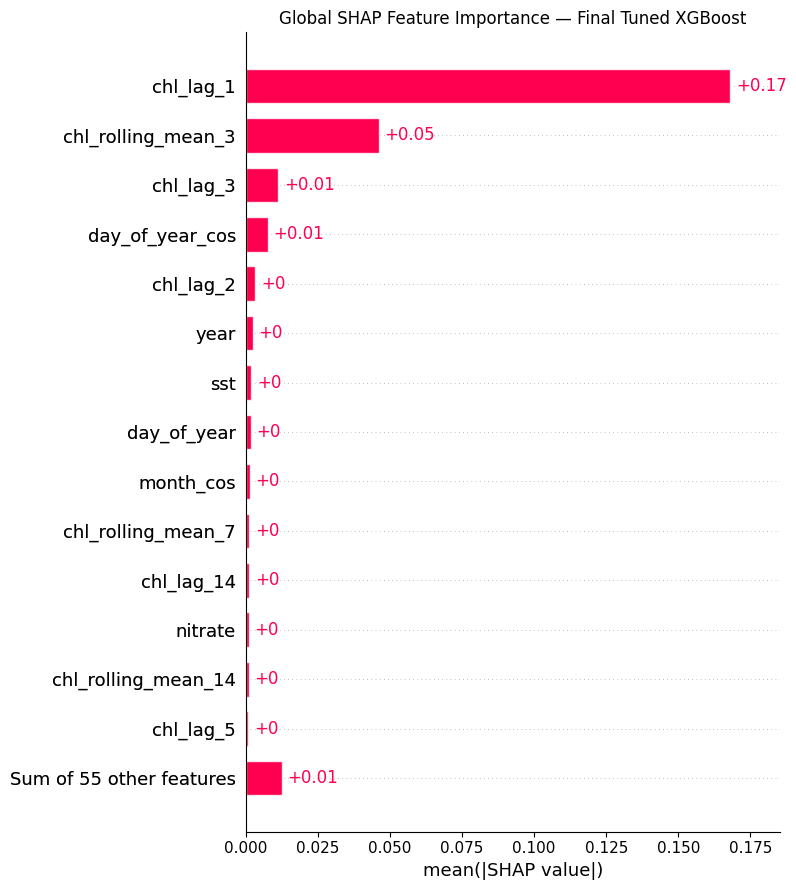

Saved global SHAP bar plot:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability/shap_global_bar_plot.png

CREATING GLOBAL SHAP BEESWARM PLOT


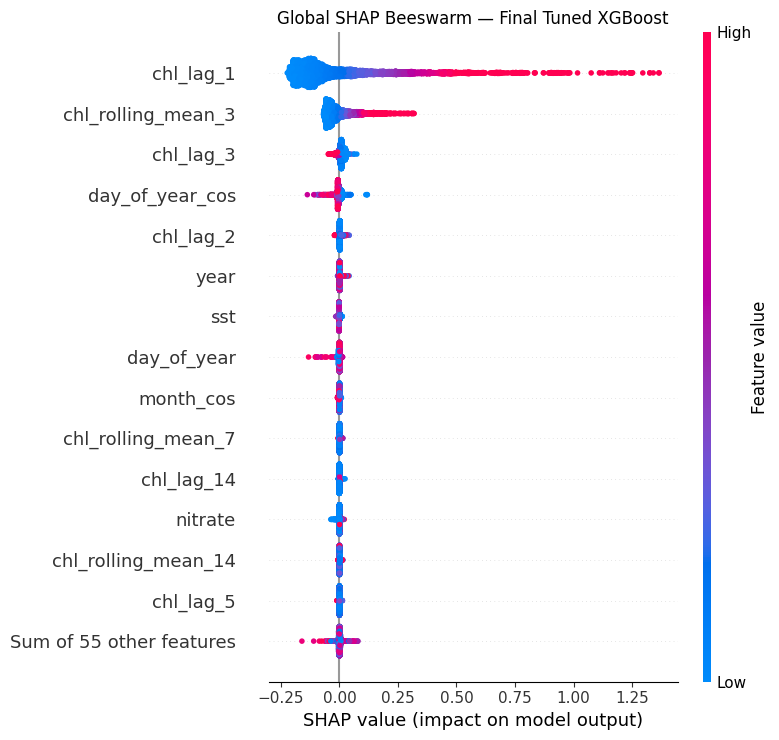

Saved global SHAP beeswarm plot:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability/shap_global_beeswarm_plot.png

TOP FEATURE ANALYSIS
Most influential feature: chl_lag_1
Mean absolute SHAP: 0.168012
Mean SHAP: -0.002200

Important: mean absolute SHAP measures overall influence, while mean SHAP describes average direction.

Saved SHAP global analysis summary:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability/shap_global_analysis_summary.json

FINAL 31.9P-16S-04 SAFETY CHECK
Saved SHAP values used       : TRUE
SHAP values recalculated     : FALSE
Model retrained              : FALSE
Hyperparameters changed      : FALSE
Model modified               : FALSE
Predictions regenerated      : FALSE
Global SHAP bar plot         : TRUE
Global SHAP beeswarm plot    : TRUE
Top-15 interpretation saved  : TRUE

✓ Global 

In [1]:
# ======================================================================
# STEP 31.9P-16S-04
# GLOBAL SHAP VISUALIZATION & INTERPRETATION
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("STEP 31.9P-16S-04")
print("GLOBAL SHAP VISUALIZATION & INTERPRETATION")
print("=" * 70)

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

FINAL_TUNED_DIR = os.path.join(
    PROJECT,
    "06_models",
    "02_XGBoost",
    "hyperparameter_optimization",
    "final_tuned_candidate"
)

SHAP_DIR = os.path.join(
    FINAL_TUNED_DIR,
    "shap_explainability"
)

SHAP_VALUES_PATH = os.path.join(
    SHAP_DIR,
    "shap_values_5000x69.csv"
)

SHAP_IMPORTANCE_PATH = os.path.join(
    SHAP_DIR,
    "shap_feature_importance.csv"
)

SHAP_SAMPLE_PATH = os.path.join(
    SHAP_DIR,
    "shap_test_sample_5000.csv"
)

BAR_PLOT_PATH = os.path.join(
    SHAP_DIR,
    "shap_global_bar_plot.png"
)

BEESWARM_PLOT_PATH = os.path.join(
    SHAP_DIR,
    "shap_global_beeswarm_plot.png"
)

TOP15_PATH = os.path.join(
    SHAP_DIR,
    "shap_top15_feature_interpretation.csv"
)

SUMMARY_PATH = os.path.join(
    SHAP_DIR,
    "shap_global_analysis_summary.json"
)

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------

EXPECTED_ROWS = 5000
EXPECTED_FEATURES = 69
TOP_N = 15

print("\n" + "=" * 70)
print("SHAP VISUALIZATION CONFIGURATION")
print("=" * 70)

print("SHAP observations :", EXPECTED_ROWS)
print("Model features    :", EXPECTED_FEATURES)
print("Top features      :", TOP_N)

# ----------------------------------------------------------------------
# REQUIRED FILE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "SHAP values": SHAP_VALUES_PATH,
    "SHAP feature importance": SHAP_IMPORTANCE_PATH,
    "SHAP sample": SHAP_SAMPLE_PATH
}

for name, path in required_files.items():

    exists = os.path.exists(path)

    print(f"{name:35s}: {exists}")

    if not exists:
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required SHAP files found.")

# ----------------------------------------------------------------------
# LOAD SHAP VALUES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING SAVED SHAP VALUES")
print("=" * 70)

shap_values_df = pd.read_csv(
    SHAP_VALUES_PATH
)

print("Saved SHAP matrix shape:", shap_values_df.shape)

if "sample_row" not in shap_values_df.columns:
    raise ValueError(
        "SHAP values file does not contain sample_row."
    )

features = [
    column
    for column in shap_values_df.columns
    if column != "sample_row"
]

print("Number of SHAP features:", len(features))

if len(features) != EXPECTED_FEATURES:
    raise ValueError(
        f"Expected {EXPECTED_FEATURES} features, "
        f"found {len(features)}."
    )

shap_values = shap_values_df[features].to_numpy(
    dtype=np.float64
)

if shap_values.shape != (
    EXPECTED_ROWS,
    EXPECTED_FEATURES
):
    raise ValueError(
        f"Unexpected SHAP matrix shape: "
        f"{shap_values.shape}"
    )

print(
    f"✓ SHAP matrix confirmed: "
    f"{EXPECTED_ROWS} × {EXPECTED_FEATURES}"
)

# ----------------------------------------------------------------------
# SHAP VALUE SAFETY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP VALUE SAFETY CHECK")
print("=" * 70)

shap_nan = int(
    np.isnan(shap_values).sum()
)

shap_infinite = int(
    np.isinf(shap_values).sum()
)

print("SHAP NaN       :", shap_nan)
print("SHAP infinite :", shap_infinite)

if shap_nan != 0 or shap_infinite != 0:
    raise ValueError(
        "Invalid SHAP values detected."
    )

print("✓ All SHAP values are finite.")

# ----------------------------------------------------------------------
# LOAD SHAP SAMPLE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING SHAP FEATURE VALUES")
print("=" * 70)

shap_sample_df = pd.read_csv(
    SHAP_SAMPLE_PATH
)

X_shap = shap_sample_df[features].copy()

print("SHAP feature matrix:", X_shap.shape)

if X_shap.shape != (
    EXPECTED_ROWS,
    EXPECTED_FEATURES
):
    raise ValueError(
        f"Unexpected feature matrix shape: "
        f"{X_shap.shape}"
    )

print("✓ SHAP feature matrix confirmed.")

# ----------------------------------------------------------------------
# LOAD IMPORTANCE TABLE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING GLOBAL SHAP IMPORTANCE")
print("=" * 70)

importance_df = pd.read_csv(
    SHAP_IMPORTANCE_PATH
)

required_importance_columns = [
    "rank",
    "feature",
    "mean_absolute_shap",
    "mean_shap"
]

missing_importance_columns = [
    column
    for column in required_importance_columns
    if column not in importance_df.columns
]

if missing_importance_columns:
    raise ValueError(
        "Missing SHAP importance columns: "
        + str(missing_importance_columns)
    )

print(
    "Importance rows:",
    len(importance_df)
)

if len(importance_df) != EXPECTED_FEATURES:
    raise ValueError(
        f"Expected {EXPECTED_FEATURES} importance rows, "
        f"found {len(importance_df)}."
    )

print("✓ Global SHAP importance table verified.")

# ----------------------------------------------------------------------
# REBUILD SHAP EXPLANATION OBJECT
# ----------------------------------------------------------------------
# This is only for visualization.
# No model training or prediction is performed.

print("\n" + "=" * 70)
print("PREPARING SHAP VISUALIZATION OBJECT")
print("=" * 70)

shap_explanation = shap.Explanation(
    values=shap_values,
    data=X_shap.to_numpy(dtype=np.float64),
    feature_names=features
)

print("✓ SHAP explanation object prepared.")
print("✓ No model retraining performed.")
print("✓ No predictions regenerated.")

# ----------------------------------------------------------------------
# DISPLAY TOP 15
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP 15 SHAP FEATURES")
print("=" * 70)

top15 = importance_df.head(TOP_N).copy()

print(
    top15[
        [
            "rank",
            "feature",
            "mean_absolute_shap",
            "mean_shap"
        ]
    ].to_string(index=False)
)

# ----------------------------------------------------------------------
# CREATE INTERPRETATION TABLE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CREATING TOP-15 INTERPRETATION TABLE")
print("=" * 70)

interpretation_rows = []

for _, row in top15.iterrows():

    mean_abs = float(
        row["mean_absolute_shap"]
    )

    mean_direction = float(
        row["mean_shap"]
    )

    if mean_direction > 0:
        direction = "Overall positive contribution"
    elif mean_direction < 0:
        direction = "Overall negative contribution"
    else:
        direction = "Approximately neutral average contribution"

    interpretation_rows.append({
        "rank": int(row["rank"]),
        "feature": row["feature"],
        "mean_absolute_shap": mean_abs,
        "mean_shap": mean_direction,
        "overall_average_direction": direction
    })

top15_interpretation_df = pd.DataFrame(
    interpretation_rows
)

print(
    top15_interpretation_df.to_string(
        index=False
    )
)

# ----------------------------------------------------------------------
# SAVE INTERPRETATION TABLE
# ----------------------------------------------------------------------

top15_interpretation_df.to_csv(
    TOP15_PATH,
    index=False
)

print("\nSaved top-15 interpretation:")
print(TOP15_PATH)

# ----------------------------------------------------------------------
# GLOBAL SHAP BAR PLOT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CREATING GLOBAL SHAP BAR PLOT")
print("=" * 70)

plt.figure(figsize=(10, 8))

shap.plots.bar(
    shap_explanation,
    max_display=TOP_N,
    show=False
)

plt.title(
    "Global SHAP Feature Importance — Final Tuned XGBoost"
)

plt.tight_layout()

plt.savefig(
    BAR_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

print("Saved global SHAP bar plot:")
print(BAR_PLOT_PATH)

# ----------------------------------------------------------------------
# GLOBAL SHAP BEESWARM PLOT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CREATING GLOBAL SHAP BEESWARM PLOT")
print("=" * 70)

plt.figure(figsize=(11, 9))

shap.plots.beeswarm(
    shap_explanation,
    max_display=TOP_N,
    show=False
)

plt.title(
    "Global SHAP Beeswarm — Final Tuned XGBoost"
)

plt.tight_layout()

plt.savefig(
    BEESWARM_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

print("Saved global SHAP beeswarm plot:")
print(BEESWARM_PLOT_PATH)

# ----------------------------------------------------------------------
# TOP FEATURE ANALYSIS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP FEATURE ANALYSIS")
print("=" * 70)

top_feature = importance_df.iloc[0]

print(
    "Most influential feature:",
    top_feature["feature"]
)

print(
    "Mean absolute SHAP:",
    f"{float(top_feature['mean_absolute_shap']):.6f}"
)

print(
    "Mean SHAP:",
    f"{float(top_feature['mean_shap']):.6f}"
)

print(
    "\nImportant:",
    "mean absolute SHAP measures overall influence,",
    "while mean SHAP describes average direction."
)

# ----------------------------------------------------------------------
# SAVE SUMMARY
# ----------------------------------------------------------------------

summary = {
    "analysis_step": "31.9P-16S-04",
    "analysis_name": "Global SHAP Visualization and Interpretation",
    "model": "Final Tuned XGBoost",
    "sample_observations": EXPECTED_ROWS,
    "number_of_features": EXPECTED_FEATURES,
    "top_n_features": TOP_N,
    "top_feature": str(top_feature["feature"]),
    "top_feature_mean_absolute_shap": float(
        top_feature["mean_absolute_shap"]
    ),
    "top_feature_mean_shap": float(
        top_feature["mean_shap"]
    ),
    "visualizations_created": [
        "global_shap_bar_plot",
        "global_shap_beeswarm_plot"
    ],
    "model_retrained": False,
    "hyperparameters_changed": False,
    "model_modified": False,
    "predictions_regenerated": False,
    "purpose": "Post-hoc global model explainability"
}

with open(
    SUMMARY_PATH,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\nSaved SHAP global analysis summary:")
print(SUMMARY_PATH)

# ----------------------------------------------------------------------
# FINAL SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL 31.9P-16S-04 SAFETY CHECK")
print("=" * 70)

print("Saved SHAP values used       : TRUE")
print("SHAP values recalculated     : FALSE")
print("Model retrained              : FALSE")
print("Hyperparameters changed      : FALSE")
print("Model modified               : FALSE")
print("Predictions regenerated      : FALSE")
print("Global SHAP bar plot         : TRUE")
print("Global SHAP beeswarm plot    : TRUE")
print("Top-15 interpretation saved  : TRUE")

print("\n✓ Global SHAP analysis completed.")
print("✓ Feature importance visualized.")
print("✓ SHAP direction visualization generated.")
print("✓ Final XGBoost remains unchanged.")

print("\n" + "=" * 70)
print("STEP 31.9P-16S-04 COMPLETE")
print("=" * 70)

print("\nNEXT STEP:")
print("31.9P-16S-05 — Local SHAP Prediction Explanation")

STEP 31.9P-16S-05
LOCAL SHAP PREDICTION EXPLANATION

LOCAL SHAP CONFIGURATION
SHAP observations       : 5000
Model features          : 69
Local cases             : 3
Top local contributors  : 10

Locked productivity thresholds:
Low / Medium : 0.212671 mg/m³
Medium / High: 0.4331 mg/m³

REQUIRED FILE CHECK
SHAP values                        : True
SHAP sample                        : True
Final configuration                : True

✓ All required SHAP files found.

LOADING SAVED SHAP VALUES
SHAP matrix shape: (5000, 69)
✓ SHAP matrix verified.

LOADING SAVED SHAP SAMPLE
SHAP sample shape: (5000, 75)
✓ SHAP sample contains 5,000 observations.
✓ 69 model features confirmed.
✓ Actual CHL target available.

LOCAL SHAP INPUT SAFETY CHECK
SHAP NaN              : 0
SHAP infinite         : 0
Feature NaN           : 0
Feature infinite     : 0
Actual CHL NaN        : 0
Actual CHL infinite   : 0

✓ Local SHAP inputs passed all safety checks.

ASSIGNING LOCKED PRODUCTIVITY CLASSES
productivity_class

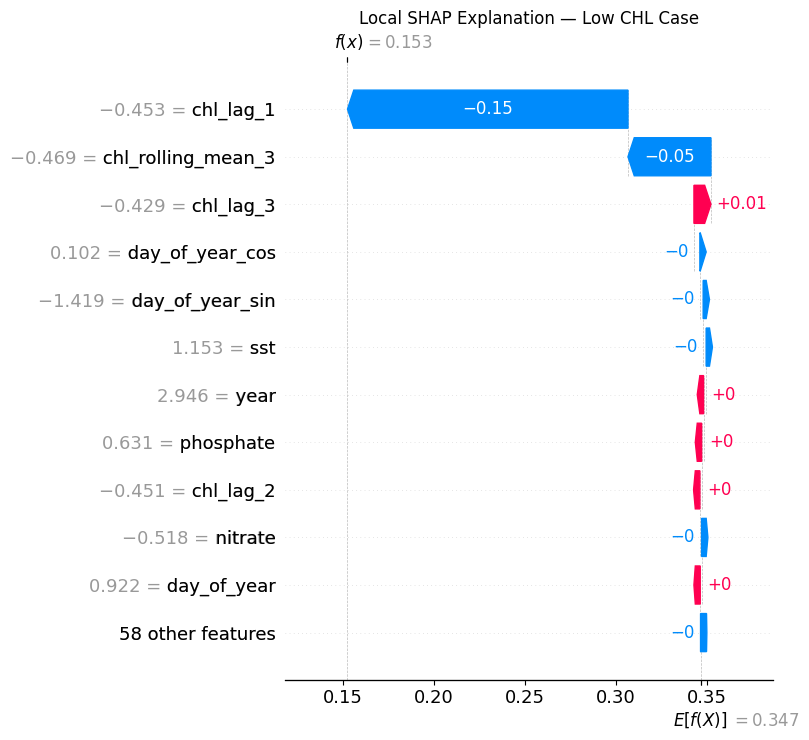

Low plot saved:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability/local_explanations/shap_local_low_case.png


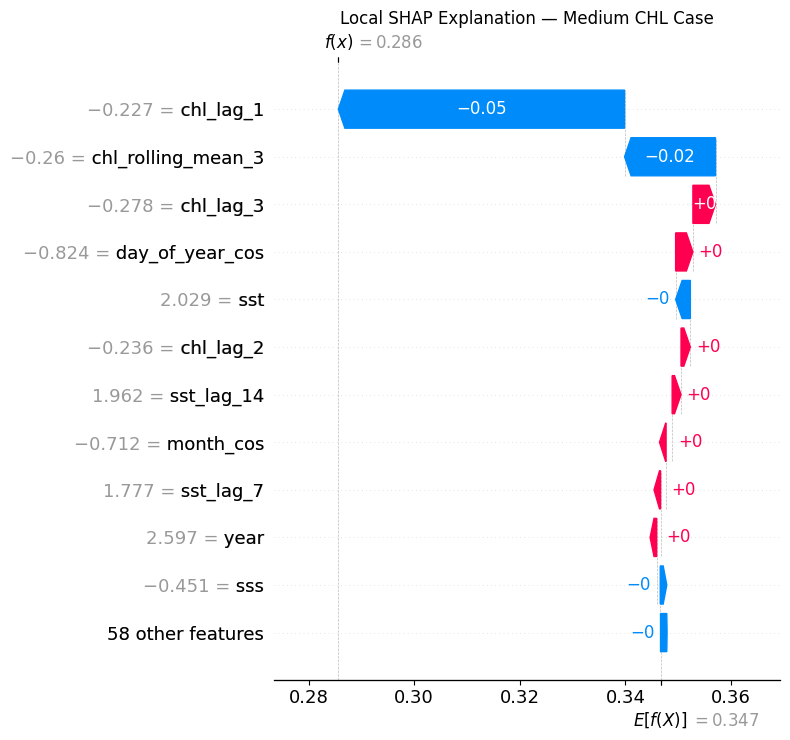

Medium plot saved:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability/local_explanations/shap_local_medium_case.png


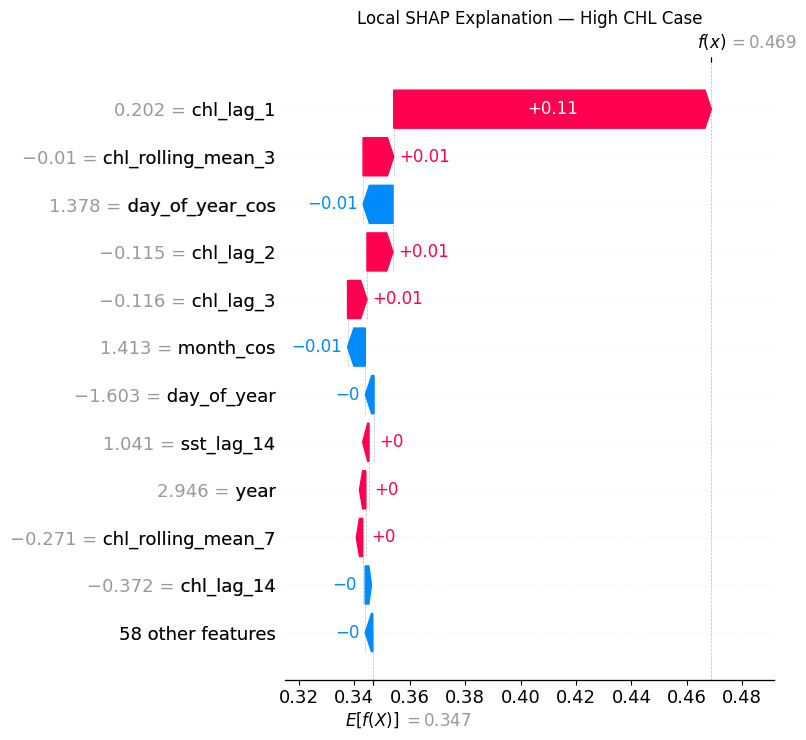

High plot saved:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability/local_explanations/shap_local_high_case.png

Saved local SHAP summary:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability/shap_local_explanation_summary.csv

Saved local SHAP contributors:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability/shap_local_top_contributors.csv

Saved local SHAP metadata:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/hyperparameter_optimization/final_tuned_candidate/shap_explainability/shap_local_explanation_metadata.json

FINAL 31.9P-16S-05 SAFETY CHECK
Saved SHAP values used       : TRUE
SHAP values recalculated     : FALSE
Model loaded for explanation : TRUE
Model retrained              : FALSE
Hyper

In [2]:
# ======================================================================
# STEP 31.9P-16S-05
# LOCAL SHAP PREDICTION EXPLANATION
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("STEP 31.9P-16S-05")
print("LOCAL SHAP PREDICTION EXPLANATION")
print("=" * 70)

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

FINAL_TUNED_DIR = os.path.join(
    PROJECT,
    "06_models",
    "02_XGBoost",
    "hyperparameter_optimization",
    "final_tuned_candidate"
)

SHAP_DIR = os.path.join(
    FINAL_TUNED_DIR,
    "shap_explainability"
)

SHAP_VALUES_PATH = os.path.join(
    SHAP_DIR,
    "shap_values_5000x69.csv"
)

SHAP_SAMPLE_PATH = os.path.join(
    SHAP_DIR,
    "shap_test_sample_5000.csv"
)

CONFIG_PATH = os.path.join(
    FINAL_TUNED_DIR,
    "xgboost_final_tuned_candidate_configuration.json"
)

LOCAL_SUMMARY_PATH = os.path.join(
    SHAP_DIR,
    "shap_local_explanation_summary.csv"
)

LOCAL_METADATA_PATH = os.path.join(
    SHAP_DIR,
    "shap_local_explanation_metadata.json"
)

LOCAL_TOP_FEATURES_PATH = os.path.join(
    SHAP_DIR,
    "shap_local_top_contributors.csv"
)

LOCAL_PLOTS_DIR = os.path.join(
    SHAP_DIR,
    "local_explanations"
)

os.makedirs(
    LOCAL_PLOTS_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# LOCKED PRODUCTIVITY THRESHOLDS
# ----------------------------------------------------------------------

LOW_MEDIUM_THRESHOLD = 0.212671
MEDIUM_HIGH_THRESHOLD = 0.433100

EXPECTED_ROWS = 5000
EXPECTED_FEATURES = 69
TOP_FEATURES = 10

print("\n" + "=" * 70)
print("LOCAL SHAP CONFIGURATION")
print("=" * 70)

print("SHAP observations       :", EXPECTED_ROWS)
print("Model features          :", EXPECTED_FEATURES)
print("Local cases             : 3")
print("Top local contributors  :", TOP_FEATURES)

print("\nLocked productivity thresholds:")
print("Low / Medium :", LOW_MEDIUM_THRESHOLD, "mg/m³")
print("Medium / High:", MEDIUM_HIGH_THRESHOLD, "mg/m³")

# ----------------------------------------------------------------------
# REQUIRED FILE CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

required_files = {
    "SHAP values": SHAP_VALUES_PATH,
    "SHAP sample": SHAP_SAMPLE_PATH,
    "Final configuration": CONFIG_PATH
}

for name, path in required_files.items():

    exists = os.path.exists(path)

    print(f"{name:35s}: {exists}")

    if not exists:
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("\n✓ All required SHAP files found.")

# ----------------------------------------------------------------------
# LOAD SHAP VALUES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING SAVED SHAP VALUES")
print("=" * 70)

shap_values_df = pd.read_csv(
    SHAP_VALUES_PATH
)

if "sample_row" not in shap_values_df.columns:
    raise ValueError(
        "sample_row column not found in SHAP values."
    )

features = [
    column
    for column in shap_values_df.columns
    if column != "sample_row"
]

shap_values = shap_values_df[
    features
].to_numpy(
    dtype=np.float64
)

print("SHAP matrix shape:", shap_values.shape)

if shap_values.shape != (
    EXPECTED_ROWS,
    EXPECTED_FEATURES
):
    raise ValueError(
        f"Expected ({EXPECTED_ROWS}, {EXPECTED_FEATURES}), "
        f"found {shap_values.shape}"
    )

print("✓ SHAP matrix verified.")

# ----------------------------------------------------------------------
# LOAD SHAP SAMPLE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING SAVED SHAP SAMPLE")
print("=" * 70)

shap_sample_df = pd.read_csv(
    SHAP_SAMPLE_PATH
)

print("SHAP sample shape:", shap_sample_df.shape)

X_shap = shap_sample_df[
    features
].copy()

if X_shap.shape != (
    EXPECTED_ROWS,
    EXPECTED_FEATURES
):
    raise ValueError(
        f"Unexpected SHAP feature matrix shape: {X_shap.shape}"
    )

required_targets = [
    "chlorophyll_a",
    "chlorophyll_a_log1p"
]

missing_targets = [
    column
    for column in required_targets
    if column not in shap_sample_df.columns
]

if missing_targets:
    raise ValueError(
        f"Missing target columns: {missing_targets}"
    )

actual_chl = shap_sample_df[
    "chlorophyll_a"
].to_numpy(
    dtype=np.float64
)

actual_log_chl = shap_sample_df[
    "chlorophyll_a_log1p"
].to_numpy(
    dtype=np.float64
)

print("✓ SHAP sample contains 5,000 observations.")
print("✓ 69 model features confirmed.")
print("✓ Actual CHL target available.")

# ----------------------------------------------------------------------
# SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOCAL SHAP INPUT SAFETY CHECK")
print("=" * 70)

shap_nan = int(
    np.isnan(shap_values).sum()
)

shap_inf = int(
    np.isinf(shap_values).sum()
)

feature_nan = int(
    X_shap.isna().sum().sum()
)

feature_inf = int(
    np.isinf(
        X_shap.to_numpy(dtype=np.float64)
    ).sum()
)

target_nan = int(
    np.isnan(actual_chl).sum()
)

target_inf = int(
    np.isinf(actual_chl).sum()
)

print("SHAP NaN              :", shap_nan)
print("SHAP infinite         :", shap_inf)
print("Feature NaN           :", feature_nan)
print("Feature infinite     :", feature_inf)
print("Actual CHL NaN        :", target_nan)
print("Actual CHL infinite   :", target_inf)

if any([
    shap_nan != 0,
    shap_inf != 0,
    feature_nan != 0,
    feature_inf != 0,
    target_nan != 0,
    target_inf != 0
]):
    raise ValueError(
        "Local SHAP safety check failed."
    )

print("\n✓ Local SHAP inputs passed all safety checks.")

# ----------------------------------------------------------------------
# CLASSIFY PRODUCTIVITY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("ASSIGNING LOCKED PRODUCTIVITY CLASSES")
print("=" * 70)

def productivity_class(value):

    if value < LOW_MEDIUM_THRESHOLD:
        return "Low"

    elif value <= MEDIUM_HIGH_THRESHOLD:
        return "Medium"

    else:
        return "High"

productivity_classes = np.array([
    productivity_class(value)
    for value in actual_chl
])

class_counts = pd.Series(
    productivity_classes
).value_counts()

print(
    pd.DataFrame({
        "productivity_class": class_counts.index,
        "observations": class_counts.values
    }).to_string(index=False)
)

for required_class in ["Low", "Medium", "High"]:

    if np.sum(
        productivity_classes == required_class
    ) == 0:

        raise ValueError(
            f"No {required_class} observations found."
        )

print("\n✓ Low, Medium and High observations available.")

# ----------------------------------------------------------------------
# SELECT REPRESENTATIVE OBSERVATION FOR EACH CLASS
# ----------------------------------------------------------------------
# We choose the observation closest to the median CHL within
# each productivity class. This avoids selecting an extreme case.

print("\n" + "=" * 70)
print("SELECTING REPRESENTATIVE LOCAL CASES")
print("=" * 70)

selected_cases = []

for class_name in ["Low", "Medium", "High"]:

    class_indices = np.where(
        productivity_classes == class_name
    )[0]

    class_values = actual_chl[class_indices]

    class_median = float(
        np.median(class_values)
    )

    closest_position = np.argmin(
        np.abs(
            class_values - class_median
        )
    )

    selected_index = int(
        class_indices[closest_position]
    )

    selected_cases.append({
        "case": class_name,
        "sample_row": selected_index,
        "actual_chlorophyll_a": float(
            actual_chl[selected_index]
        ),
        "actual_chlorophyll_a_log1p": float(
            actual_log_chl[selected_index]
        ),
        "class_median_chlorophyll_a": class_median
    })

    print(
        f"{class_name:8s} | "
        f"sample_row={selected_index:4d} | "
        f"actual CHL={actual_chl[selected_index]:.6f} mg/m³"
    )

selected_cases_df = pd.DataFrame(
    selected_cases
)

print("\n✓ Three representative local cases selected.")

# ----------------------------------------------------------------------
# LOAD MODEL CONFIGURATION
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING FINAL MODEL CONFIGURATION")
print("=" * 70)

with open(
    CONFIG_PATH,
    "r"
) as f:

    config = json.load(f)

print("Model:", config.get("model"))
print("Target:", config.get("target"))
print("Best iteration:", config.get("best_iteration"))
print("Best trees:", config.get("best_number_of_trees"))

# ----------------------------------------------------------------------
# DETERMINE SHAP BASE VALUE
# ----------------------------------------------------------------------
# The SHAP values were generated for the finalized model.
# We use TreeExplainer only to obtain the expected/base value.
# No prediction is generated and no model is modified.

print("\n" + "=" * 70)
print("OBTAINING SHAP BASE VALUE")
print("=" * 70)

import xgboost as xgb

MODEL_PATH = os.path.join(
    FINAL_TUNED_DIR,
    "xgboost_final_tuned_candidate.json"
)

model = xgb.XGBRegressor()

model.load_model(
    MODEL_PATH
)

explainer = shap.TreeExplainer(
    model
)

expected_value = np.asarray(
    explainer.expected_value
)

if expected_value.size != 1:

    raise ValueError(
        f"Unexpected SHAP expected value: {expected_value}"
    )

base_value = float(
    expected_value.reshape(-1)[0]
)

print(
    "SHAP base value:",
    f"{base_value:.10f}"
)

print("✓ SHAP base value obtained.")

# ----------------------------------------------------------------------
# RECONSTRUCT LOCAL LOG-SCALE PREDICTIONS
# ----------------------------------------------------------------------
# SHAP additivity:
#
# prediction_log = base_value + sum(SHAP values)
#
# This reconstructs the already-explained model output.
# It does NOT retrain or generate a new model prediction.

print("\n" + "=" * 70)
print("RECONSTRUCTING EXPLAINED MODEL OUTPUT")
print("=" * 70)

local_rows = []

for case in selected_cases:

    index = int(
        case["sample_row"]
    )

    local_shap = shap_values[index]

    predicted_log = (
        base_value +
        np.sum(local_shap)
    )

    predicted_chl = np.expm1(
        predicted_log
    )

    actual_value = float(
        actual_chl[index]
    )

    local_rows.append({
        "case": case["case"],
        "sample_row": index,
        "actual_chlorophyll_a_mg_m3": actual_value,
        "explained_predicted_log1p": float(
            predicted_log
        ),
        "explained_predicted_chlorophyll_a_mg_m3": float(
            predicted_chl
        ),
        "absolute_error_mg_m3": float(
            abs(
                actual_value -
                predicted_chl
            )
        ),
        "productivity_class": case["case"]
    })

local_summary_df = pd.DataFrame(
    local_rows
)

print(
    local_summary_df.to_string(
        index=False
    )
)

# ----------------------------------------------------------------------
# LOCAL SHAP CONTRIBUTOR TABLE
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP LOCAL SHAP CONTRIBUTORS")
print("=" * 70)

local_contributor_rows = []

for case in selected_cases:

    index = int(
        case["sample_row"]
    )

    local_shap = shap_values[index]

    absolute_values = np.abs(
        local_shap
    )

    top_indices = np.argsort(
        absolute_values
    )[::-1][:TOP_FEATURES]

    for rank, feature_index in enumerate(
        top_indices,
        start=1
    ):

        contribution = float(
            local_shap[feature_index]
        )

        if contribution > 0:
            direction = "Pushes prediction higher"
        elif contribution < 0:
            direction = "Pushes prediction lower"
        else:
            direction = "Approximately neutral"

        local_contributor_rows.append({
            "case": case["case"],
            "sample_row": index,
            "rank": rank,
            "feature": features[feature_index],
            "feature_value": float(
                X_shap.iloc[
                    index,
                    feature_index
                ]
            ),
            "shap_value": contribution,
            "absolute_shap_value": float(
                abs(contribution)
            ),
            "direction": direction
        })

local_contributors_df = pd.DataFrame(
    local_contributor_rows
)

for case_name in ["Low", "Medium", "High"]:

    print("\n" + "-" * 70)
    print(
        f"{case_name.upper()} CASE — TOP CONTRIBUTORS"
    )
    print("-" * 70)

    print(
        local_contributors_df[
            local_contributors_df["case"] == case_name
        ].to_string(index=False)
    )

# ----------------------------------------------------------------------
# CREATE LOCAL WATERFALL PLOTS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CREATING LOCAL SHAP WATERFALL PLOTS")
print("=" * 70)

for case in selected_cases:

    case_name = case["case"]
    index = int(
        case["sample_row"]
    )

    local_explanation = shap.Explanation(
        values=shap_values[index],
        base_values=base_value,
        data=X_shap.iloc[index].to_numpy(
            dtype=np.float64
        ),
        feature_names=features
    )

    plot_path = os.path.join(
        LOCAL_PLOTS_DIR,
        f"shap_local_{case_name.lower()}_case.png"
    )

    plt.figure(
        figsize=(10, 8)
    )

    shap.plots.waterfall(
        local_explanation,
        max_display=12,
        show=False
    )

    plt.title(
        f"Local SHAP Explanation — {case_name} CHL Case"
    )

    plt.tight_layout()

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print(
        f"{case_name} plot saved:"
    )
    print(plot_path)

# ----------------------------------------------------------------------
# SAVE LOCAL SUMMARY
# ----------------------------------------------------------------------

local_summary_df.to_csv(
    LOCAL_SUMMARY_PATH,
    index=False
)

print("\nSaved local SHAP summary:")
print(LOCAL_SUMMARY_PATH)

# ----------------------------------------------------------------------
# SAVE LOCAL CONTRIBUTORS
# ----------------------------------------------------------------------

local_contributors_df.to_csv(
    LOCAL_TOP_FEATURES_PATH,
    index=False
)

print("\nSaved local SHAP contributors:")
print(LOCAL_TOP_FEATURES_PATH)

# ----------------------------------------------------------------------
# SAVE METADATA
# ----------------------------------------------------------------------

metadata = {
    "analysis_step": "31.9P-16S-05",
    "analysis_name": "Local SHAP Prediction Explanation",
    "model": "Final Tuned XGBoost",
    "sample_size": EXPECTED_ROWS,
    "number_of_features": EXPECTED_FEATURES,
    "number_of_local_cases": 3,
    "selected_cases": [
        "Low",
        "Medium",
        "High"
    ],
    "selection_method": (
        "Observation closest to the median CHL "
        "within each locked productivity class"
    ),
    "low_medium_threshold_mg_m3": LOW_MEDIUM_THRESHOLD,
    "medium_high_threshold_mg_m3": MEDIUM_HIGH_THRESHOLD,
    "top_local_features_per_case": TOP_FEATURES,
    "model_retrained": False,
    "hyperparameters_changed": False,
    "model_modified": False,
    "new_predictions_generated": False,
    "purpose": "Post-hoc local model explainability"
}

with open(
    LOCAL_METADATA_PATH,
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print("\nSaved local SHAP metadata:")
print(LOCAL_METADATA_PATH)

# ----------------------------------------------------------------------
# FINAL SAFETY CHECK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL 31.9P-16S-05 SAFETY CHECK")
print("=" * 70)

print("Saved SHAP values used       : TRUE")
print("SHAP values recalculated     : FALSE")
print("Model loaded for explanation : TRUE")
print("Model retrained              : FALSE")
print("Hyperparameters changed      : FALSE")
print("Model modified               : FALSE")
print("New model predictions        : FALSE")
print("Local SHAP cases             : 3")
print("Low case                     : TRUE")
print("Medium case                  : TRUE")
print("High case                    : TRUE")
print("Local waterfall plots        : TRUE")
print("Local contributor table      : TRUE")

print("\n✓ Local SHAP explanations completed.")
print("✓ Low, Medium and High cases explained.")
print("✓ Top local contributors identified.")
print("✓ Local waterfall plots saved.")
print("✓ Final XGBoost remains unchanged.")

print("\n" + "=" * 70)
print("STEP 31.9P-16S-05 COMPLETE")
print("=" * 70)

print("\nNEXT STEP:")
print("31.9P-16S-06 — Final SHAP Verification")